In [18]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np 
import pandas as pd

Understanding Data :

In [5]:
df = sns.load_dataset("titanic")

print(f"First 5 Rows : \n{df.head(5)}")

print(f"Dataset Dimensions : \n{df.shape}")

print(f"Column Names And Data Types : \n{df.dtypes}")

print(f"Dataset Information : ")
df.info()

print(f"Descriptive Statistics : \n{df.describe()}")

print(f"Missing Values : \n{df.isnull().sum()}")

print(f"\nDuplicate Rows:\n{df.duplicated().sum()}")

First 5 Rows : 
   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  
Dataset Dimensions : 
(891, 15)
Column Names And Data Types : 
survived          int64
pclass            int64
sex                 str
age             float64
sibsp             int64
parch             in

In [ ]:
Survival Rate - Fare

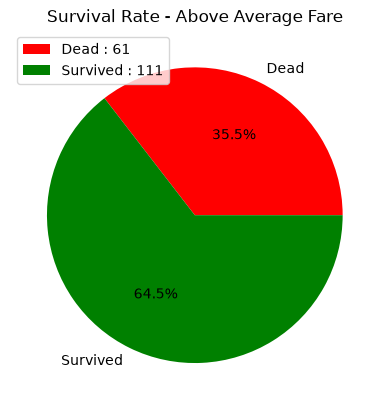

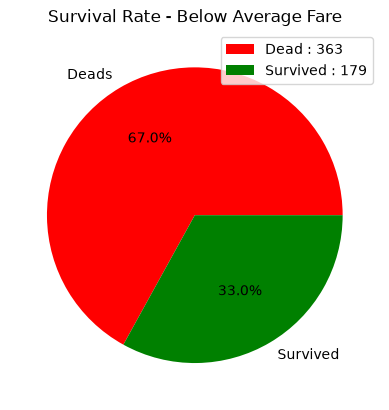

In [133]:
if df["fare"].isna().sum()>0:
    df = df.dropna(subset = "fare")
    

above_average = df[df["fare"]>=df["fare"].mean()]
below_average = df[df["fare"]<df["fare"].mean()]

counts_above_average = above_average.groupby("survived").size().reindex([0,1])
counts_below_below_average = below_average.groupby("survived").size().reindex([0,1])

plt.pie(counts_above_average , labels = ["Dead" , "Survived"] , colors = ["red" , "green"] , autopct = "%1.1f%%")
plt.title("Survival Rate - Above Average Fare")
plt.legend(labels = [f"Dead : {counts_above_average[0]} " , f"Survived : {counts_above_average[1]}"])
plt.show()

plt.pie(counts_below_below_average , labels = ["Deads" , "Survived"] , colors = ["red" , "green"] , autopct = "%1.1f%%")
plt.title("Survival Rate - Below Average Fare")
plt.legend(labels =  [f"Dead : {counts_below_below_average[0]} " , f"Survived : {counts_below_below_average[1]}"])
plt.show()

In [ ]:
Survival Rate - pclass

Survival Rate - pclass_1 :


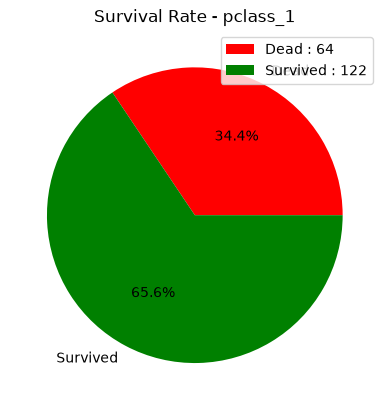

Survival Rate - pclass_2 :


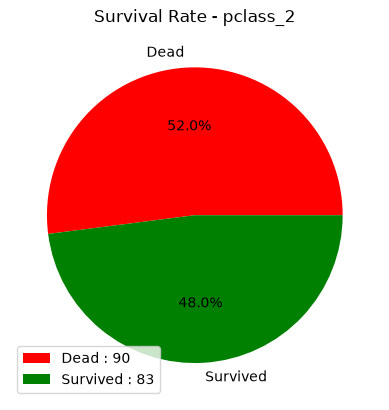

Survival Rate - pclass_3 :


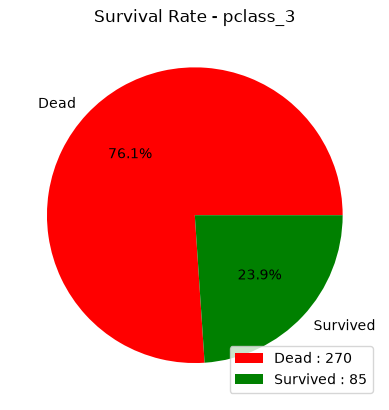

In [156]:
if df["pclass"].isna().sum()>0:
    df = df.dropna(subset = "pclass")
    

pclass_1 = df[df["pclass"] == 1]
pclass_2 = df[df["pclass"] == 2]
pclass_3 = df[df["pclass"] == 3]

counts_pclass_1 = pclass_1.groupby("survived").size().reindex([0,1])
counts_pclass_2 = pclass_2.groupby("survived").size().reindex([0,1])
counts_pclass_3 = pclass_3.groupby("survived").size().reindex([0,1])

print("Survival Rate - pclass_1 :")

plt.pie(counts_pclass_1 , labels = ["Dead" , "Survived"] , colors = ["red" , "green"] , autopct = "%1.1f%%")
plt.title("Survival Rate - pclass_1")
plt.legend(labels = [f"Dead : {counts_pclass_1[0]} " , f"Survived : {counts_pclass_1[1]}"])
plt.show()

print("Survival Rate - pclass_2 :")

plt.pie(counts_pclass_2 , labels = ["Dead" , "Survived"] , colors = ["red" , "green"] , autopct = "%1.1f%%")
plt.title("Survival Rate - pclass_2")
plt.legend(labels = [f"Dead : {counts_pclass_2[0]} " , f"Survived : {counts_pclass_2[1]}"])
plt.show()

print("Survival Rate - pclass_3 :")

plt.pie(counts_pclass_3 , labels = ["Dead" , "Survived"] , colors = ["red" , "green"] , autopct = "%1.1f%%")
plt.title("Survival Rate - pclass_3")
plt.legend(labels = [f"Dead : {counts_pclass_3[0]} " , f"Survived : {counts_pclass_3[1]}"])
plt.show()

Survival Rate - Age

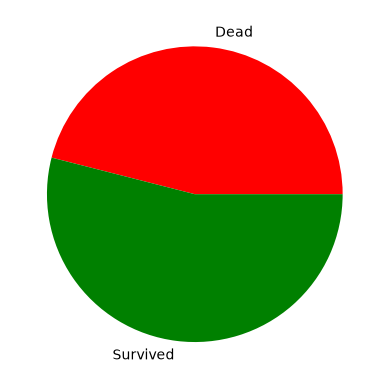

In [155]:
if df["age"].isna().sum()>0:
    df = df.dropna(subset = ["age"])

child = df[df["age"]<18]
Young =df[ (df["age"]>=18) & (df["age"]<=35)]
Middle_Aged = df[(df["age"]>=36) & (df["age"]<=59)]
old = df[df["age"]>=60]

dead_child = (child["survived"] == 0).sum()
survived_child = (child["survived"] == 1).sum()

dead_Young = (Young["survived"] == 0).sum()
survived_Young = (Young["survived"] == 1).sum()

dead_Middle_Aged = (Middle_Aged["survived"] == 0).sum()
survived_Middle_Aged = (Middle_Aged["survived"] == 1).sum()

dead_old = (old["survived"] == 0).sum()
survived_old = (old["survived"] == 1).sum()

plt.pie([dead_child , survived_child] , labels = ["Dead" , "Survived"] , colors = ["red" , "green"] , autopct = "%1.1f%%")
plt.title("Survival Rate - Child")
plt.


In [78]:
colums_df = df.columns

for i in colums_df:

    if df[i].dtype == "int64":

        if df[i].min() >= 0 and df[i].max() <= 255:
            df[i] = df[i].astype("uint8")

        elif df[i].min() >= 0 and df[i].max() <= 65535:
            df[i] = df[i].astype("uint16")

        elif df[i].min() >= 0 and df[i].max() <= 4294967295:
            df[i] = df[i].astype("uint32")

        elif df[i].min() >= 0 and df[i].max() <= 18446744073709551615:
            df[i] = df[i].astype("uint64")

    elif df[i].dtype == "float64":
        df[i] = df[i].astype("float32")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    uint8   
 1   pclass       891 non-null    uint8   
 2   sex          891 non-null    str     
 3   age          714 non-null    float32 
 4   sibsp        891 non-null    uint8   
 5   parch        891 non-null    uint8   
 6   fare         891 non-null    float32 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float32(2), str(5), uint8(4)
memory usage: 49.3 KB


In [59]:
survived_check = ((df["survived"] == 0 )& (df["alive"] == "no")) | ((df["survived"] == 1 )& (df["alive"] == "yes"))
pclass_check = (df["pclass"]>=1) | (df["pclass"]<=3)
sex_check = ((df["sex"] == "male") & (df["who"] == "men")) | ((df["sex"] == "female")&(df["who"] == "woman"))
std_age = np.std(df["age"])

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True
